## Fractals

Four classic fractals, each a few lines of MATLAB. The first two iterate $z \mapsto z^2 + c$ on a whole grid of complex numbers at once, so there is no loop over pixels: each step updates every point that has not escaped yet.

### The Mandelbrot and Julia sets

A point $c$ is in the Mandelbrot set when $z_{k+1} = z_k^2 + c$, starting from $z_0 = 0$, stays bounded. Once $|z| > 2$ it escapes for sure, so the picture colors each point by the step at which it escaped. The Julia set of a fixed $c$ (here $-0.8 + 0.156i$) varies the starting point instead. Raise the grid sizes for a sharper picture.

424 of 1920 grid points stayed bounded


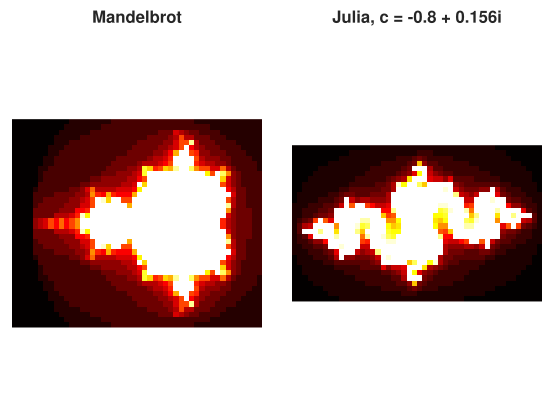

In [ ]:
figure
[re, im] = meshgrid(linspace(-2.2, 0.8, 48), linspace(-1.25, 1.25, 40));
c = re + 1i*im;
z = zeros(size(c));
escape = zeros(size(c));
for k = 1:20
    inside = abs(z) <= 2;
    z(inside) = z(inside).^2 + c(inside);
    escape(inside) = k;
end
[jr, ji] = meshgrid(linspace(-1.6, 1.6, 48), linspace(-1, 1, 30));
w = jr + 1i*ji;
steps = zeros(size(w));
for k = 1:25
    alive = abs(w) <= 2;
    w(alive) = w(alive).^2 + (-0.8 + 0.156i);
    steps(alive) = k;
end
subplot(1, 2, 1), imagesc(escape), axis equal tight off, title('Mandelbrot')
subplot(1, 2, 2), imagesc(steps), axis equal tight off, title('Julia, c = -0.8 + 0.156i')
colormap(hot)
fprintf('%d of %d grid points stayed bounded\n', nnz(escape == 20), numel(escape))

### The Barnsley fern and the logistic map

The fern is an iterated function system: four affine maps, one picked at random at each step with fixed probabilities; the points the iteration visits draw a fern. Here 2000 independent starting points iterate together, a vector at a time. The logistic map $x_{k+1} = r\,x_k(1 - x_k)$ settles to one value for small $r$, then to 2, 4, 8, ... values, and turns chaotic near $r \approx 3.57$; for each $r$ the diagram marks where the iteration ends up.

Tens of thousands of points would make a heavy figure, so both are drawn as images on a coarse grid: the fern's picture counts the points that fall in each cell (`accumarray`), a density shown on a log scale, and the logistic map's marks each cell its orbits visit.

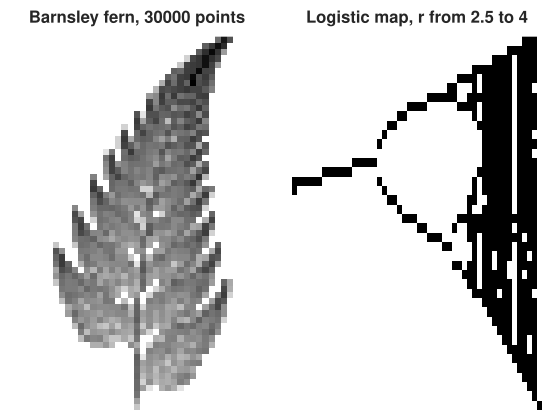

In [ ]:
figure
rng(1);
chains = 2000;
fx = zeros(chains, 1); fy = zeros(chains, 1);
P = zeros(0, 2);
for k = 1:25
    r = rand(chains, 1);
    m1 = r < 0.01; m2 = r >= 0.01 & r < 0.86; m3 = r >= 0.86 & r < 0.93; m4 = r >= 0.93;
    gx = zeros(chains, 1); gy = zeros(chains, 1);
    gy(m1) = 0.16*fy(m1);
    gx(m2) = 0.85*fx(m2) + 0.04*fy(m2);  gy(m2) = -0.04*fx(m2) + 0.85*fy(m2) + 1.6;
    gx(m3) = 0.2*fx(m3) - 0.26*fy(m3);   gy(m3) = 0.23*fx(m3) + 0.22*fy(m3) + 1.6;
    gx(m4) = -0.15*fx(m4) + 0.28*fy(m4); gy(m4) = 0.26*fx(m4) + 0.24*fy(m4) + 0.44;
    fx = gx; fy = gy;
    if k > 10
        P = [P; fx, fy];
    end
end
% (each point's grid cell: rows from the top, columns from the left)
row = min(60, 1 + floor((10 - P(:, 2)) / 10 * 60));
col = min(33, 1 + floor((P(:, 1) + 2.75) / 5.5 * 33));
fern = accumarray([row, col], 1, [60 33]);
rs = linspace(2.5, 4, 50);
xs = 0.5 * ones(size(rs));
for k = 1:300
    xs = rs .* xs .* (1 - xs);
end
orbit = zeros(40, numel(rs));
for k = 1:200
    xs = rs .* xs .* (1 - xs);
    rowk = min(40, 1 + floor((1 - xs) * 40));
    orbit(sub2ind(size(orbit), rowk, 1:numel(rs))) = 1;
end
subplot(1, 2, 1), imagesc(log(1 + fern)), axis equal tight off, title(sprintf('Barnsley fern, %d points', size(P, 1)))
subplot(1, 2, 2), imagesc(orbit), axis tight off, title('Logistic map, r from 2.5 to 4')
colormap(flipud(gray))

*Topics after examples in MatRust-Studio (MIT license); the code here is Sagebrush's own.*